# 03 · Duygu Analizi: Müşteri Yorumları Ne Anlatıyor?

Siparişlerin ~%41'inde müşteri, puanın yanına Portekizce bir yorum da yazmış.
Bu notebook bu yorumları üç açıdan inceler:

1. **Kim yorum yazıyor?** Yorum yazma davranışı puana göre nasıl değişiyor?
2. **Duygu modeli:** Metinden yorumun olumlu mu olumsuz mu olduğunu tahmin eden bir model (TF-IDF + lojistik regresyon). Puanlar etiket olarak kullanıldı: 1–2 puan olumsuz, 4–5 puan olumlu.
3. **Şikâyet konuları:** Olumsuz yorumlarda müşteriler en çok neden şikâyet ediyor?

> Ön eğitimli büyük dil modelleri yerine sade ve yorumlanabilir bir yöntem tercih edildi: modelin hangi kelimelere dayandığı doğrudan okunabiliyor.

In [1]:
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

import ortak
from ortak import CAMGOBEGI, MAVI, SOLUK, TURUNCU, YAZI, YUZDE, kaydet, sayi

ortak.stil_uygula()
t = ortak.tablolari_yukle()
df = ortak.siparis_tablosu(t)

s = t["siparisler"]
donem = s[(s["order_purchase_timestamp"] >= ortak.BASLANGIC) & (s["order_purchase_timestamp"] < ortak.BITIS)]
yorum = ortak.son_yorumlar(t).merge(donem[["order_id", "order_status"]], on="order_id")

# Teslimat durumu: sistemde teslim edilmemiş / geç / zamanında
gec = df.set_index("order_id")["gec"]
yorum["teslimat"] = np.select(
    [yorum["order_id"].map(gec).eq(True), yorum["order_id"].map(gec).eq(False)],
    ["Geç teslim", "Zamanında teslim"], default="Teslim edilmedi")
yorum["yazili"] = yorum["review_comment_message"].notna()
print(f"Yorumlanan sipariş: {sayi(len(yorum))} | metin içeren: {sayi(yorum['yazili'].sum())} "
      f"(%{sayi(yorum['yazili'].mean() * 100, 1)})")

Yorumlanan sipariş: 98.330 | metin içeren: 40.523 (%41,2)


## 1. Kim yorum yazıyor?

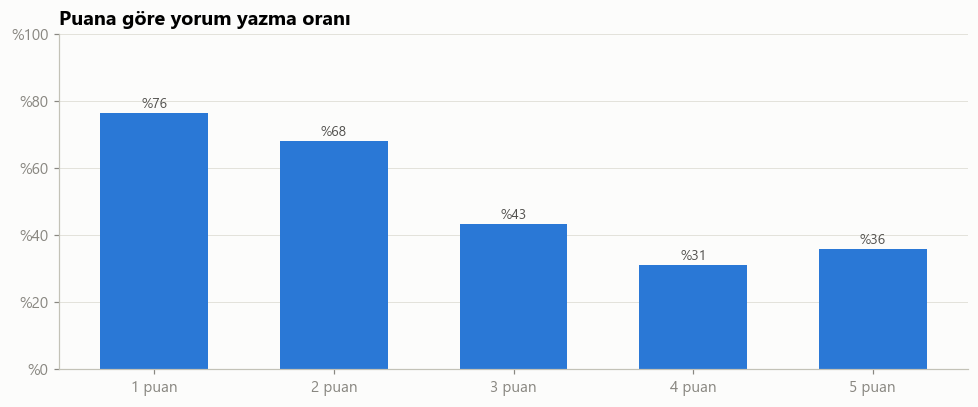

In [2]:
oran = yorum.groupby("review_score")["yazili"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(oran.index, oran.values, color=MAVI, width=0.6)
for x, v in oran.items():
    ax.text(x, v + 1.5, f"%{sayi(v)}", ha="center", color=YAZI, fontsize=9)
ax.set_xticks(oran.index, [f"{p} puan" for p in oran.index])
ax.yaxis.set_major_formatter(YUZDE)
ax.set_ylim(0, 100)
ax.set_title("Puana göre yorum yazma oranı")
ax.grid(axis="x", visible=False)
fig.tight_layout()
kaydet(fig, "nlp_01_yorum_orani")
plt.show()

Memnun olmayan müşteri **konuşuyor**: 1 puan veren müşterilerin büyük çoğunluğu yorum yazarken, 5 puan verenlerde bu oran çok daha düşük.
Bu yüzden yorum metinleri, olumsuz deneyimleri anlamak için değerli bir kaynak.

## 2. Metin temizleme

- Küçük harfe çevirme ve Portekizce aksanları kaldırma (`não` → `nao`)
- Harf dışındaki karakterleri silme
- Durak kelimeleri (de, que, para…) atma. Olumsuzluk bildiren **nao, nem, nunca, sem, ainda, so** kelimeleri bilerek korundu, çünkü "nao recebi" (almadım) gibi ifadeler en güçlü sinyaller.

In [3]:
DURAK = set("""
a ao aos aquela aquelas aquele aqueles aquilo as ate com como da das de dela delas dele deles depois do dos
e ela elas ele eles em entre era eram essa essas esse esses esta estas este estes estou estava eu foi fomos
for foram fui ha isso isto ja lhe lhes mais mas me mesmo meu meus minha minhas muito muita na nas no nos nossa
nosso num numa o os ou para pela pelas pelo pelos por pra qual quando que quem se seja seu seus sua suas
tambem te tem ter teu tu um uma umas uns voce voces vc ser sao tive tinha q pq la aqui cada ne ai to
""".split())


def sade(metin):
    """Küçük harf, aksansız, yalnızca harf ve rakam."""
    metin = unicodedata.normalize("NFKD", str(metin).lower())
    metin = "".join(c for c in metin if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", " ", metin).strip()


def temizle(metin):
    return " ".join(k for k in sade(metin).split() if k not in DURAK and len(k) > 1 and not k.isdigit())


yazili = yorum[yorum["yazili"]].copy()
yazili["sade"] = yazili["review_comment_message"].map(sade)
yazili["metin"] = yazili["review_comment_message"].map(temizle)
yazili = yazili[yazili["metin"].str.len() > 0]
yazili[["review_score", "review_comment_message", "metin"]].head(5)

,review_score,review_comment_message,metin
0,5,Adorei o produto! Super recomendo o lojista. R...,adorei produto super recomendo lojista recebi ...
2,5,"Loja recomendada, produto era como anunciado e...",loja recomendada produto anunciado entrega bem...
3,5,O produto chegou com bastante antescedencia e ...,produto chegou bastante antescedencia fiquei f...
4,5,Comprei 2 produtos no mesmo pedido com os srs ...,comprei produtos pedido srs chegou falta fique...
7,4,"Pensava que era maior, mas tbm não tinha noção...",pensava maior tbm nao nocao cm fora lindinha a...


## 3. Duygu modeli

3 puanlı (kararsız) yorumlar eğitimden çıkarıldı. Veri %80 eğitim / %20 test olarak ayrıldı.
Kelimelerin yanında **ikili kelime grupları** (bigram) da kullanıldı ki "nao recebi" gibi ifadeler tek bir sinyal olarak yakalanabilsin.

In [4]:
etiketli = yazili[yazili["review_score"] != 3].assign(olumsuz=lambda t: (t["review_score"] <= 2).astype(int))
X_egitim, X_test, y_egitim, y_test = train_test_split(
    etiketli["metin"], etiketli["olumsuz"], test_size=0.2, stratify=etiketli["olumsuz"], random_state=42)

duygu = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True),
    LogisticRegression(max_iter=2000, class_weight="balanced", C=2.0))
duygu.fit(X_egitim, y_egitim)

olasilik = duygu.predict_proba(X_test)[:, 1]
tahmin = (olasilik >= 0.5).astype(int)
print(f"Eğitim: {sayi(len(X_egitim))} yorum | test: {sayi(len(X_test))} yorum | "
      f"olumsuz oranı: %{sayi(etiketli['olumsuz'].mean() * 100, 1)}")
print(f"ROC-AUC: {sayi(roc_auc_score(y_test, olasilik), 3)}\n")
print(classification_report(y_test, tahmin, target_names=["Olumlu", "Olumsuz"], digits=3))
pd.DataFrame(confusion_matrix(y_test, tahmin),
             index=["Gerçek: olumlu", "Gerçek: olumsuz"], columns=["Tahmin: olumlu", "Tahmin: olumsuz"])

Eğitim: 29.443 yorum | test: 7.361 yorum | olumsuz oranı: %29,1
ROC-AUC: 0,976

              precision    recall  f1-score   support

      Olumlu      0.975     0.924     0.949      5217
     Olumsuz      0.836     0.943     0.886      2144

    accuracy                          0.929      7361
   macro avg      0.906     0.933     0.918      7361
weighted avg      0.935     0.929     0.931      7361



,Tahmin: olumlu,Tahmin: olumsuz
Gerçek: olumlu,4821,396
Gerçek: olumsuz,123,2021


In [5]:
kelimeler = duygu[0].get_feature_names_out()
agirlik = pd.Series(duygu[1].coef_[0], index=kelimeler).sort_values()
print("Olumsuz yönde en güçlü 20:", ", ".join(agirlik.tail(20).index[::-1]))
print("Olumlu yönde en güçlü 20:", ", ".join(agirlik.head(20).index))

Olumsuz yönde en güçlü 20: nao, nao recomendo, pessimo, comprei, nao gostei, pessima, nao recebi, ruim, inferior, nem, aguardando, faltando, horrivel, diferente, quebrado, quero, nao chegou, recebi apenas, defeito, nao entregue
Olumlu yönde en güçlü 20: recomendo, excelente, parabens, lindo, rapida, antes, tudo, perfeito, otima, rapido, amei, gostei, adorei, obrigada, so nao, bem, satisfeita, boa, otimo, satisfeito


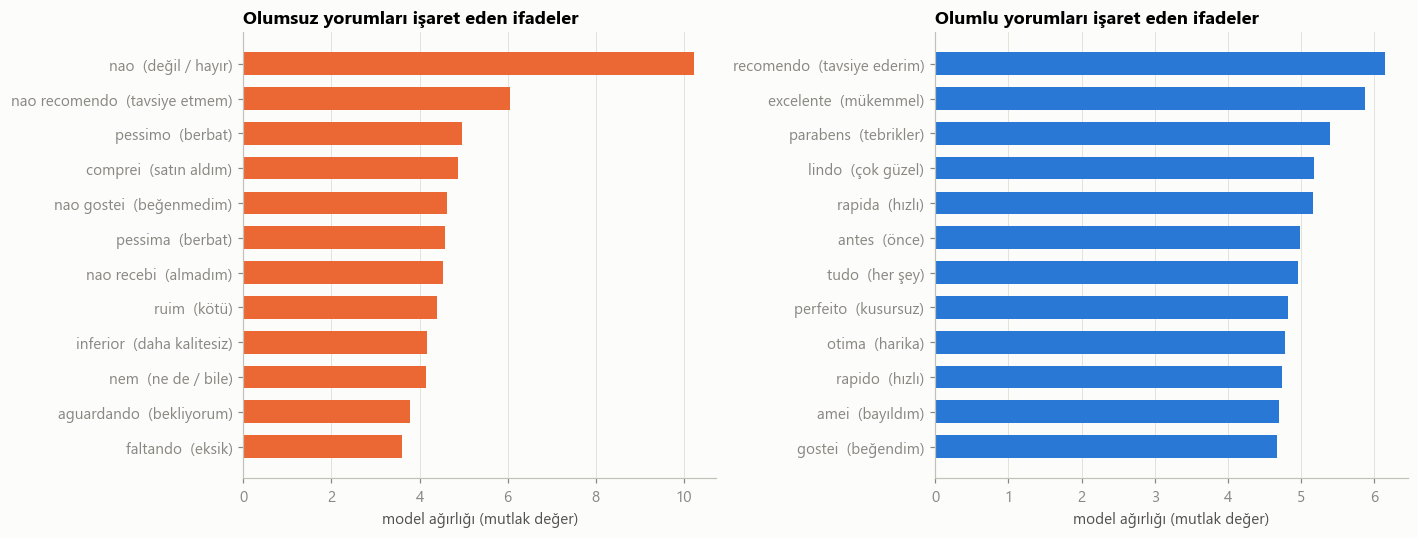

In [6]:
CEVIRI = {  # grafikte gösterilen ifadelerin Türkçe karşılıkları
    "nao": "değil / hayır", "nao recomendo": "tavsiye etmem", "pessimo": "berbat", "pessima": "berbat",
    "comprei": "satın aldım", "nao gostei": "beğenmedim", "nao recebi": "almadım", "ruim": "kötü",
    "inferior": "daha kalitesiz", "nem": "ne de / bile", "aguardando": "bekliyorum", "faltando": "eksik",
    "recomendo": "tavsiye ederim", "excelente": "mükemmel", "parabens": "tebrikler", "lindo": "çok güzel",
    "rapida": "hızlı", "rapido": "hızlı", "antes": "önce", "tudo": "her şey", "perfeito": "kusursuz",
    "otima": "harika", "amei": "bayıldım", "gostei": "beğendim",
}

n = 12
olumsuz_k = agirlik.tail(n)
olumlu_k = agirlik.head(n).iloc[::-1].abs()
etiket = lambda k: f"{k}  ({CEVIRI[k]})" if k in CEVIRI else k

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.barh([etiket(k) for k in olumsuz_k.index], olumsuz_k.values, color=TURUNCU, height=0.65)
ax1.set_title("Olumsuz yorumları işaret eden ifadeler", fontsize=12)
ax2.barh([etiket(k) for k in olumlu_k.index], olumlu_k.values, color=MAVI, height=0.65)
ax2.set_title("Olumlu yorumları işaret eden ifadeler", fontsize=12)
for ax in (ax1, ax2):
    ax.set_xlabel("model ağırlığı (mutlak değer)")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
kaydet(fig, "nlp_02_kelimeler")
plt.show()

Model olumsuz yorumları iki tür ifadeden tanıyor. Birincisi açık memnuniyetsizlik: "nao recomendo" (tavsiye etmem), "pessimo" (berbat), "nao gostei" (beğenmedim).
İkincisi teslimat ve eksiklik sorunları: "nao recebi" (almadım), "aguardando" (bekliyorum), "faltando" (eksik).
Olumlu tarafta "recomendo" (tavsiye ederim), "excelente" (mükemmel) ve "parabens" (tebrikler) ile birlikte **hız** öne çıkıyor: "rapida/rapido" (hızlı), "antes" (süreden önce).

### 3 puanlı yorumlar ve puan–metin uyumsuzlukları
Model, eğitimde görmediği 3 puanlı yorumlara ve tüm yorumlara uygulanarak iki soru soruldu:
3 puan veren kararsız müşteriler aslında ne yazıyor? Puanı ile yazdığı metin çelişen müşteri var mı?

In [7]:
yazili["p_olumsuz"] = duygu.predict_proba(yazili["metin"])[:, 1]
uc = yazili[yazili["review_score"] == 3]
print(f"3 puanlı yorumlarda metni olumsuz sınıflandırılanların oranı: %{sayi((uc['p_olumsuz'] >= 0.5).mean() * 100)}")

celiski = yazili[(yazili["review_score"] == 5) & (yazili["p_olumsuz"] >= 0.9)]
print(f"5 puan verip metni güçlü biçimde olumsuz olan yorum: {sayi(len(celiski))} "
      f"(5 puanlı yazılı yorumlar içindeki payı: %{sayi(len(celiski) / (yazili['review_score'] == 5).sum() * 100, 1)})")
pd.set_option("display.max_colwidth", 120)
celiski.sort_values("p_olumsuz", ascending=False)[["review_score", "p_olumsuz", "review_comment_message"]].head(6)

3 puanlı yorumlarda metni olumsuz sınıflandırılanların oranı: %59
5 puan verip metni güçlü biçimde olumsuz olan yorum: 111 (5 puanlı yazılı yorumlar içindeki payı: %0,5)


,review_score,p_olumsuz,review_comment_message
78493,5,1.00,Não recebi
69164,5,1.00,Não recebi
4585,5,1.00,vendeiro um produto que não tinh\a
58801,5,1.00,Não recebi o produto
62770,5,1.00,Não recebi o produto
79880,5,1.00,Produto não entregue.


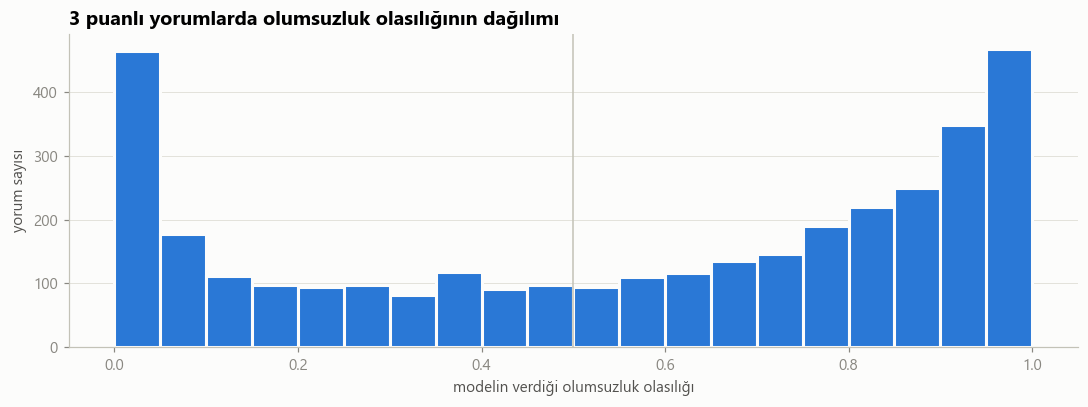

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(uc["p_olumsuz"], bins=np.linspace(0, 1, 21), color=MAVI, edgecolor=ortak.YUZEY, linewidth=2)
ax.axvline(0.5, color=ortak.ORTA_GRI, linewidth=1)
ax.set_title("3 puanlı yorumlarda olumsuzluk olasılığının dağılımı")
ax.set_xlabel("modelin verdiği olumsuzluk olasılığı")
ax.set_ylabel("yorum sayısı")
ax.grid(axis="x", visible=False)
fig.tight_layout()
kaydet(fig, "nlp_03_uc_puan")
plt.show()

3 puanlı yorumların ~%59'u metin olarak olumsuz sınıflandırılıyor. Yani "orta" puan veren müşterilerin çoğu aslında bir sorun yaşamış.
5 puan verip "ürünü almadım" yazan müşteriler de var. Puan ölçeğini ters anlayan bu müşteriler, puan ortalamasının olduğundan biraz iyi görünmesine yol açıyor.

## 4. Şikâyet konuları

1–2 puanlı yorumlar, anahtar kelime kurallarıyla yedi şikâyet konusuna ayrıldı.
Bir yorum birden fazla konuya girebilir (örneğin "geç geldi ve kırıktı").
Kurallar, aksanları kaldırılmış ama durak kelimeleri korunmuş metin (`sade`) üzerinde çalışır.

C:\Users\fazfu\AppData\Local\Temp\ipykernel_17816\640866045.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  olumsuz[konu] = olumsuz["sade"].str.contains(desen, regex=True)
C:\Users\fazfu\AppData\Local\Temp\ipykernel_17816\640866045.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  olumsuz[konu] = olumsuz["sade"].str.contains(desen, regex=True)


Olumsuz yazılı yorum: 10.721 | en az bir konuya giren: %72,6


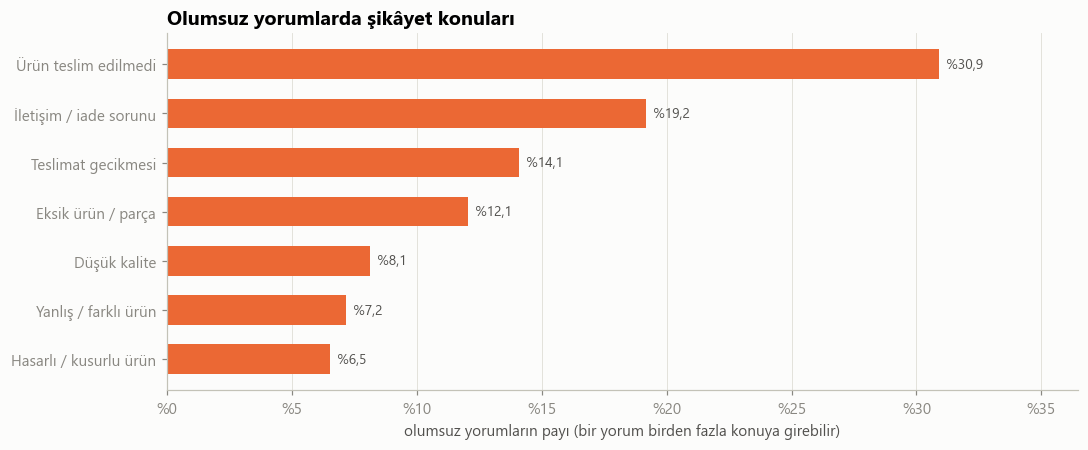

In [9]:
KONULAR = {
    "Ürün teslim edilmedi": r"\bnao (recebi|chegou|foi entregue|entregaram|recebemos)|\bainda nao\b|aguardando|nunca chegou",
    "Teslimat gecikmesi": r"atras|demor|\bprazo",
    "Eksik ürün / parça": r"\bfalt|incomplet|\bso (veio|recebi|chegou)|(veio|recebi|chegou) (apenas|so)\b|\bmetade\b",
    "Yanlış / farklı ürün": r"errad|diferente|outro produto|trocad",
    "Hasarlı / kusurlu ürün": r"quebrad|defeit|danificad|avariad|estragad|nao funciona|amassad|rasgad|riscad",
    "Düşük kalite": r"qualidade|pessim|\bruim|fragil|frageis|material",
    "İletişim / iade sorunu": r"respost|respond|contato|atendimento|devol|reembols|estorn|cancel|dinheiro",
}
olumsuz = yazili[yazili["review_score"] <= 2].copy()
for konu, desen in KONULAR.items():
    olumsuz[konu] = olumsuz["sade"].str.contains(desen, regex=True)
olumsuz["herhangi"] = olumsuz[list(KONULAR)].any(axis=1)
print(f"Olumsuz yazılı yorum: {sayi(len(olumsuz))} | en az bir konuya giren: %{sayi(olumsuz['herhangi'].mean() * 100, 1)}")

pay = olumsuz[list(KONULAR)].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(pay.index, pay.values, color=TURUNCU, height=0.6)
for i, v in enumerate(pay.values):
    ax.text(v, i, f"  %{sayi(v, 1)}", va="center", color=YAZI, fontsize=9)
ax.xaxis.set_major_formatter(YUZDE)
ax.set_xlim(0, pay.max() * 1.18)
ax.set_title("Olumsuz yorumlarda şikâyet konuları")
ax.set_xlabel("olumsuz yorumların payı (bir yorum birden fazla konuya girebilir)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
kaydet(fig, "nlp_04_sikayet_konulari")
plt.show()

In [10]:
capraz = (olumsuz.groupby("teslimat")[list(KONULAR)].mean() * 100).T
capraz = capraz[["Zamanında teslim", "Geç teslim", "Teslim edilmedi"]]
capraz.loc["yorum sayısı"] = olumsuz["teslimat"].value_counts()[capraz.columns]
capraz.round(1)

teslimat,Zamanında teslim,Geç teslim,Teslim edilmedi
Ürün teslim edilmedi,17.30,55.20,44.80
Teslimat gecikmesi,8.40,25.70,17.40
Eksik ürün / parça,17.10,4.50,4.50
Yanlış / farklı ürün,10.80,1.60,2.00
Hasarlı / kusurlu ürün,10.20,0.90,1.00
Düşük kalite,10.20,5.00,5.20
İletişim / iade sorunu,17.80,15.10,31.90
yorum sayısı,"6,442.00","2,739.00","1,540.00"


In [11]:
almadim = olumsuz[olumsuz["Ürün teslim edilmedi"]]
print(f"'Ürünü almadım' diyen olumsuz yorum: {sayi(len(almadim))}")
print(almadim["teslimat"].value_counts(normalize=True).mul(100).round(1).rename("sistemdeki durum (%)").to_string())

'Ürünü almadım' diyen olumsuz yorum: 3.313
teslimat
Geç teslim         45.60
Zamanında teslim   33.60
Teslim edilmedi    20.80


**Sistemde teslim edilmiş görünen siparişlerde neden "almadım" yazılıyor?**
Olist, değerlendirme anketini ürün gerçekten ulaştığında değil, **tahmini teslim tarihi civarında** gönderiyor gibi görünüyor.
Bunu test etmek için anketin oluşturulma tarihi ile gerçek teslim tarihi karşılaştırıldı.

In [12]:
teslim_tarihi = df.set_index("order_id")["order_delivered_customer_date"].dt.normalize()
yorum["teslim_tarihi"] = yorum["order_id"].map(teslim_tarihi)
yorum["anket_once"] = yorum["review_creation_date"] < yorum["teslim_tarihi"]
teslim_edilen = yorum[yorum["teslimat"] != "Teslim edilmedi"]
anket = teslim_edilen.groupby("teslimat").agg(
    siparis=("order_id", "count"), anket_teslimden_once=("anket_once", "mean"), ort_puan=("review_score", "mean"))
anket["anket_teslimden_once"] *= 100
print("Anketi ürün ulaşmadan gönderilen siparişlerde ortalama puan:",
      sayi(teslim_edilen.loc[teslim_edilen["anket_once"], "review_score"].mean(), 2))
print("Anketi ürün ulaştıktan sonra gönderilen geç siparişlerde ortalama puan:",
      sayi(teslim_edilen.loc[~teslim_edilen["anket_once"] & (teslim_edilen["teslimat"] == "Geç teslim"), "review_score"].mean(), 2))
anket.rename(columns={"anket_teslimden_once": "anket ürün ulaşmadan (%)"})

Anketi ürün ulaşmadan gönderilen siparişlerde ortalama puan: 1,93
Anketi ürün ulaştıktan sonra gönderilen geç siparişlerde ortalama puan: 3,53


,siparis,anket ürün ulaşmadan (%),ort_puan
teslimat,,,
Geç teslim,6378,74.46,2.27
Zamanında teslim,89182,0.25,4.29


## 5. Bulgular

| # | Bulgu |
|---|---|
| 1 | Memnun olmayan müşteri daha çok yazıyor: 1 puan verenlerin **%76**'sı yorum yazarken 4 puan verenlerde bu oran **%31**. |
| 2 | Basit bir TF-IDF + lojistik regresyon modeli, yorumun olumlu mu olumsuz mu olduğunu **%93 doğrulukla** (ROC-AUC 0,976) tahmin ediyor ve olumsuz yorumların %94'ünü yakalıyor. |
| 3 | 3 puanlı yorumların ~**%59**'u metin olarak olumsuz. 111 müşteri ise 5 puan verip "ürünü almadım" gibi olumsuz bir metin yazmış; puan ölçeğinin her zaman doğru kullanılmadığını gösteriyor. |
| 4 | Olumsuz yorumların en sık konusu **ürünün teslim edilmemesi (%31)**. Onu iletişim/iade sorunları (%19) ve gecikme (%14) izliyor. |
| 5 | Teslimat zamanında olduğunda şikâyetler **ürüne** kayıyor: zamanında teslim edilen olumsuz yorumlarda eksik ürün (%17), yanlış ürün (%11), hasar (%10) ve kalite (%10) şikâyetleri, geç teslim edilenlere göre 2–11 kat daha sık. |
| 6 | **Geç teslim edilen siparişlerin ~%75'inde değerlendirme anketi ürün ulaşmadan gönderilmiş.** "Almadım" diyen geç sipariş yorumlarının çoğu, ürün henüz yoldayken yazılmış. Geç teslimatın puana etkisinin bir kısmı, anketin zamanlamasından kaynaklanıyor. |
| 7 | Buna karşın sistemde **zamanında teslim edilmiş** görünen ~1.100 siparişte müşteri ürünü almadığını yazıyor. Kısmi teslimat, yanlış adres veya hatalı teslim kaydı olabilir; ayrıca incelenmeli. |

**Öneriler**
- Değerlendirme anketi tahmini tarihte değil, **gerçek teslimattan sonra** gönderilmeli. Bu hem puanları daha adil hale getirir hem de "almadım" şikâyetlerini azaltır.
- "Teslim edildi" görünüp müşterinin almadığını söylediği siparişler için kargo firmalarıyla teslim kanıtı (imza/fotoğraf) süreci kurulmalı.
- Duygu modeli, yeni gelen yorumları otomatik olarak önceliklendirmek için kullanılabilir. Olumsuzluk olasılığı yüksek ve "teslim edilmedi" konusuna giren yorumlar müşteri hizmetlerine ilk sırada düşmeli.